# Customer Growth Analytics
## Segmentation, observed repeat purchasing and commercial priorities
**Work in Progress · v0.1 · real public data.**

Business question: which historical customer groups merit investigation for retention, reactivation or development?
This is an executed analytical exercise, not evidence of a campaign or business impact.

Source: Chen, D. (2015), [Online Retail, UCI](https://doi.org/10.24432/C5BW33), CC BY 4.0.
Transactions cover December 2010 to December 2011. Historical findings do not describe today's market.
AI assisted preparation of this notebook. No Kaggle execution or independent validation is claimed.


## 1. Reproducible data loading
Attach the original `Online Retail.xlsx` in Kaggle, or enable Internet to download the original UCI ZIP.
Set `DATA_PATH` to select a specific file. Candidate paths are sorted; multiple candidates require an explicit selection.
No credentials or synthetic fallback are used. Raw data and customer-level outputs are not committed to GitHub.


In [1]:
from pathlib import Path
import os, json, hashlib, urllib.request, zipfile, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

SOURCE_URL = 'https://archive.ics.uci.edu/static/public/352/online+retail.zip'
OUTPUT = Path('/kaggle/working/customer-growth-output') if Path('/kaggle').exists() else Path('output')
OUTPUT.mkdir(parents=True, exist_ok=True)
explicit = os.environ.get('DATA_PATH')
candidates = sorted(Path('/kaggle/input').rglob('Online Retail.xlsx')) if Path('/kaggle/input').exists() else []
if explicit:
    data_path = Path(explicit)
elif len(candidates) == 1:
    data_path = candidates[0]
elif len(candidates) > 1:
    raise ValueError('Multiple source files found. Set DATA_PATH explicitly.')
else:
    cache = Path('data'); cache.mkdir(exist_ok=True)
    data_path = cache / 'Online Retail.xlsx'
    if not data_path.exists():
        archive = cache / 'online-retail.zip'
        urllib.request.urlretrieve(SOURCE_URL, archive)
        with zipfile.ZipFile(archive) as z:
            with z.open('Online Retail.xlsx') as source, data_path.open('wb') as target:
                target.write(source.read())
source_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
raw = pd.read_excel(data_path, engine='openpyxl')
required = {'InvoiceNo','StockCode','Description','Quantity','InvoiceDate','UnitPrice','CustomerID','Country'}
assert required <= set(raw.columns), 'Unexpected source schema'
assert len(raw) == 541909, 'This analysis expects the original UCI Online Retail file'
print('Source rows:', len(raw), '\nSHA256:', source_hash)
print('Versions:', {'python':platform.python_version(), 'pandas':pd.__version__, 'numpy':np.__version__, 'matplotlib':matplotlib.__version__})


Source rows: 541909 
SHA256: 43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d
Versions: {'python': '3.12.14', 'pandas': '3.0.1', 'numpy': '2.3.5', 'matplotlib': '3.11.2'}


## 2. Quality audit and analysis population
Rows are invoice lines, not orders or customers. Diagnostics overlap; the exclusion waterfall is sequential.
Remove exact duplicate rows as a documented assumption (they could be legitimate repeated lines).
For customer purchase behavior, exclude missing customer IDs, cancellation invoices, nonpositive quantities or prices,
and invalid dates. Cancellation exclusion means amounts below are **positive purchase value in GBP, not net revenue or profit**.
Use full calendar months December 2010–November 2011; exclude partial December 2011.
Customers first observed during the window are not necessarily genuinely new customers.


In [2]:
diagnostics = pd.DataFrame([
    ['raw_rows',len(raw)], ['exact_duplicate_rows',int(raw.duplicated().sum())],
    ['missing_customer_id',int(raw.CustomerID.isna().sum())],
    ['cancellation_lines',int(raw.InvoiceNo.astype(str).str.upper().str.startswith('C').sum())],
    ['nonpositive_quantity',int((raw.Quantity <= 0).sum())],
    ['nonpositive_price',int((raw.UnitPrice <= 0).sum())],
    ['missing_description',int(raw.Description.isna().sum())]
],columns=['diagnostic','rows'])
waterfall = []
d = raw.copy()
def keep(frame, mask, reason):
    waterfall.append({'step':reason,'removed':int((~mask).sum()),'remaining':int(mask.sum())})
    return frame.loc[mask].copy()
d = keep(d, ~d.duplicated(), 'exact duplicates')
d = keep(d, d.CustomerID.notna(), 'missing customer ID')
d = keep(d, ~d.InvoiceNo.astype(str).str.upper().str.startswith('C'), 'cancellation invoices')
d = keep(d, (d.Quantity > 0) & (d.UnitPrice > 0), 'nonpositive quantity or price')
d['InvoiceDate'] = pd.to_datetime(d.InvoiceDate, errors='coerce')
d = keep(d, d.InvoiceDate.notna(), 'invalid dates')
START, END = pd.Timestamp('2010-12-01'), pd.Timestamp('2011-12-01')
d = keep(d, (d.InvoiceDate >= START) & (d.InvoiceDate < END), 'outside complete-month window')
d['CustomerID'] = d.CustomerID.astype('int64').astype(str)
d['InvoiceNo'] = d.InvoiceNo.astype(str)
d['PurchaseValue'] = d.Quantity * d.UnitPrice
d['Month'] = d.InvoiceDate.dt.to_period('M')
waterfall = pd.DataFrame(waterfall)
assert len(raw) - waterfall.removed.sum() == len(d)
assert not d.duplicated(subset=list(raw.columns)).any()
assert d.CustomerID.notna().all() and (d.PurchaseValue > 0).all()
print(diagnostics.to_string(index=False))
print('\nSequential exclusions:\n'+waterfall.to_string(index=False))
diagnostics.to_csv(OUTPUT/'quality-diagnostics.csv',index=False)
waterfall.to_csv(OUTPUT/'cleaning-waterfall.csv',index=False)


          diagnostic   rows
            raw_rows 541909
exact_duplicate_rows   5268
 missing_customer_id 135080
  cancellation_lines   9288
nonpositive_quantity  10624
   nonpositive_price   2517
 missing_description   1454

Sequential exclusions:
                         step  removed  remaining
             exact duplicates     5268     536641
          missing customer ID   135037     401604
        cancellation invoices     8872     392732
nonpositive quantity or price       40     392692
                invalid dates        0     392692
outside complete-month window    17026     375666


## 3. Purchase patterns
Orders count distinct invoices, not lines. Monthly totals reflect known-customer positive purchases after cleaning.
The first month and last partial month are different coverage issues: the latter is excluded; the former remains left-censored.


         customers  orders  purchase_value_gbp
Month                                         
2010-12        885    1400           570422.73
2011-01        741     987           568101.31
2011-02        758     997           446084.92
2011-03        974    1321           594081.76
2011-04        856    1149           468374.33
2011-05       1056    1555           677355.15
2011-06        991    1393           660046.05
2011-07        949    1331           598962.90
2011-08        935    1280           644051.04
2011-09       1266    1755           950690.20
2011-10       1364    1929          1035642.45
2011-11       1664    2657          1156205.61


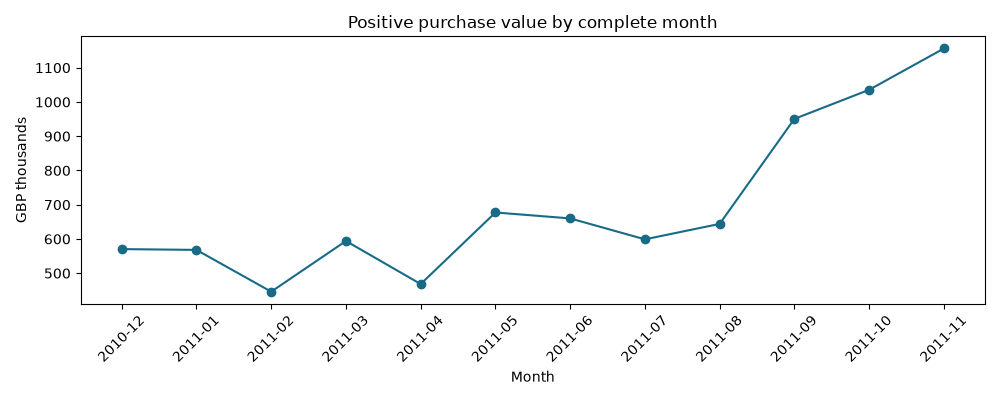

In [3]:
monthly = d.groupby('Month').agg(customers=('CustomerID','nunique'), orders=('InvoiceNo','nunique'), purchase_value_gbp=('PurchaseValue','sum'))
print(monthly.round(2).to_string())
monthly.to_csv(OUTPUT/'monthly-summary.csv')
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(monthly.index.astype(str),monthly.purchase_value_gbp/1000,marker='o',color='#176b87')
ax.set(title='Positive purchase value by complete month',ylabel='GBP thousands',xlabel='Month')
ax.tick_params(axis='x',rotation=45); fig.tight_layout()
fig.savefig(OUTPUT/'monthly-purchases.svg'); fig.savefig(OUTPUT/'monthly-purchases.png',dpi=120)
plt.show()


## 4. RFM and transparent action segments
Snapshot: **1 December 2011**, one day after the final included calendar date.
Recency uses whole calendar days since last purchase. Frequency is distinct invoices. Monetary value is positive purchase value.
R/F/M scores use percentile ranks with average ties, so equal raw values receive equal scores; bins need not be equally sized.

Action segments use explicit rules in precedence order: active high value (R≤60, F≥3, M≥75th percentile),
lapsed high value (R>90, M≥75th percentile), recent single purchase (F=1, R≤30),
active repeat (F≥2, R≤60), then other. These are descriptive labels, not predicted churn or lifetime value.


High-value threshold (GBP): 1594.23
                        customers  purchase_value_gbp  median_recency  median_orders  customer_share  value_share
segment                                                                                                          
Active high value             852         5803972.730            14.0            8.0          0.1983       0.6934
Active repeat                1038          885740.841            20.0            3.0          0.2416       0.1058
Lapsed high value             107          444633.891           140.0            4.0          0.0249       0.0531
Other                        2033         1144313.482           147.0            1.0          0.4731       0.1367
Recent single purchase        267           91357.510            16.0            1.0          0.0621       0.0109


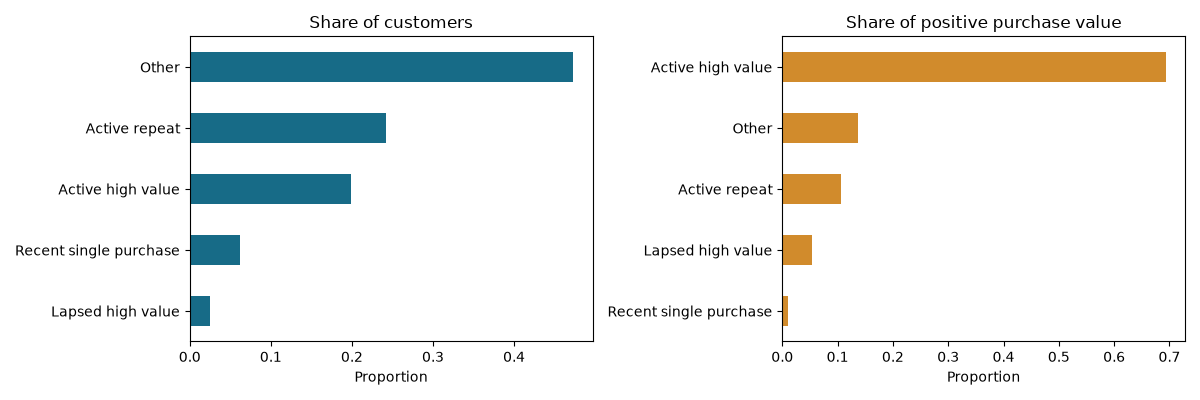

In [4]:
def make_rfm(frame, snapshot, active_days=60, lapsed_days=90, value_quantile=.75):
    r = frame.groupby('CustomerID').agg(last_purchase=('InvoiceDate','max'),frequency=('InvoiceNo','nunique'),monetary=('PurchaseValue','sum'))
    r['recency'] = (snapshot.normalize()-r.last_purchase.dt.normalize()).dt.days
    for col, ascending in [('recency',False),('frequency',True),('monetary',True)]:
        r[col+'_score'] = np.ceil(r[col].rank(method='average',pct=True,ascending=ascending)*5).clip(1,5).astype(int)
    threshold = r.monetary.quantile(value_quantile)
    r['segment'] = np.select([
        (r.recency<=active_days)&(r.frequency>=3)&(r.monetary>=threshold),
        (r.recency>lapsed_days)&(r.monetary>=threshold),
        (r.frequency==1)&(r.recency<=30),
        (r.frequency>=2)&(r.recency<=active_days)
    ], ['Active high value','Lapsed high value','Recent single purchase','Active repeat'],default='Other')
    return r, float(threshold)
rfm, value_threshold = make_rfm(d, END)
segments = rfm.groupby('segment').agg(customers=('frequency','size'),purchase_value_gbp=('monetary','sum'),median_recency=('recency','median'),median_orders=('frequency','median'))
segments['customer_share'] = segments.customers / len(rfm)
segments['value_share'] = segments.purchase_value_gbp / rfm.monetary.sum()
assert segments.customers.sum() == d.CustomerID.nunique()
assert np.isclose(segments.purchase_value_gbp.sum(), d.PurchaseValue.sum())
print('High-value threshold (GBP):',round(value_threshold,2))
print(segments.round(4).to_string())
segments.to_csv(OUTPUT/'segment-summary.csv')
fig, axes = plt.subplots(1,2,figsize=(12,4))
segments.customer_share.sort_values().plot.barh(ax=axes[0],color='#176b87')
segments.value_share.sort_values().plot.barh(ax=axes[1],color='#d18b2c')
axes[0].set(title='Share of customers',xlabel='Proportion',ylabel='')
axes[1].set(title='Share of positive purchase value',xlabel='Proportion',ylabel='')
fig.tight_layout(); fig.savefig(OUTPUT/'segment-shares.svg'); fig.savefig(OUTPUT/'segment-shares.png',dpi=120)
plt.show()


## 5. Observed cohort repeat purchasing
Group customers by their first **observed** purchase month. Each cell is the proportion purchasing in that later month,
not continuous retention or contractual churn. Customers can skip months and return. Unobserved future cells stay missing.
Comparisons are descriptive: cohort age, seasonality and left-censoring affect interpretation.


age       0      1      2      3      4      5      6      7      8      9      10     11
cohort                                                                                   
2010-12  1.0  0.366  0.323  0.384  0.363  0.398  0.363  0.349  0.354  0.395  0.374  0.503
2011-01  1.0  0.221  0.266  0.230  0.321  0.288  0.247  0.242  0.300  0.326  0.365    NaN
2011-02  1.0  0.187  0.187  0.284  0.271  0.247  0.253  0.279  0.247  0.305    NaN    NaN
2011-03  1.0  0.150  0.252  0.199  0.223  0.168  0.268  0.230  0.279    NaN    NaN    NaN
2011-04  1.0  0.213  0.203  0.210  0.197  0.227  0.217  0.260    NaN    NaN    NaN    NaN
2011-05  1.0  0.190  0.173  0.173  0.208  0.232  0.264    NaN    NaN    NaN    NaN    NaN
2011-06  1.0  0.174  0.157  0.264  0.231  0.335    NaN    NaN    NaN    NaN    NaN    NaN
2011-07  1.0  0.181  0.207  0.223  0.271    NaN    NaN    NaN    NaN    NaN    NaN    NaN
2011-08  1.0  0.207  0.249  0.243    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN
2011-09  1

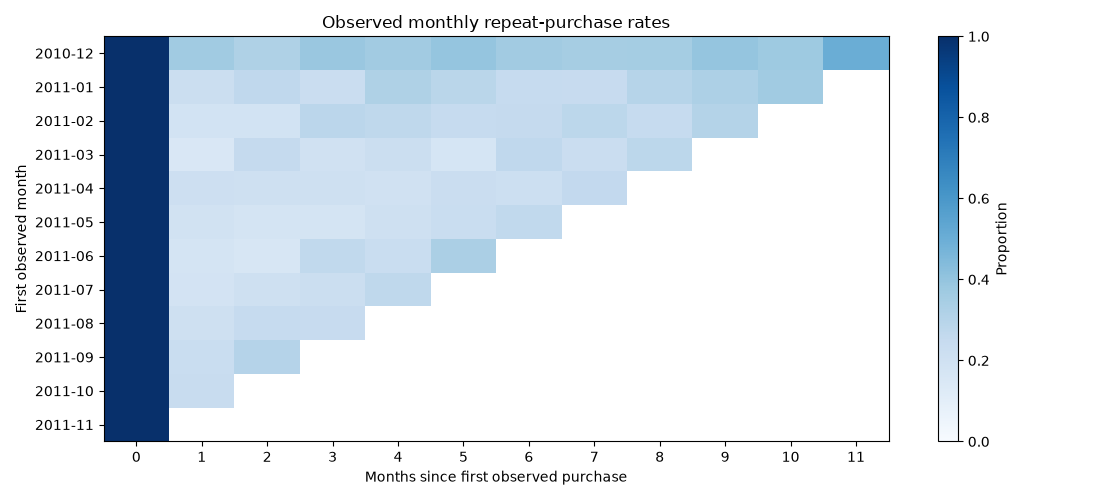

In [5]:
activity = d[['CustomerID','Month']].drop_duplicates().copy()
activity['cohort'] = activity.groupby('CustomerID').Month.transform('min')
activity['age'] = (activity.Month.astype('int64')-activity.cohort.astype('int64')).astype(int)
counts = activity.groupby(['cohort','age']).CustomerID.nunique().unstack()
cohort = counts.div(counts[0],axis=0)
assert np.allclose(cohort[0],1)
observed_rates = cohort.stack().dropna()
assert ((observed_rates>=0)&(observed_rates<=1)).all()
cohort.to_csv(OUTPUT/'cohort-repeat-rates.csv')
print(cohort.round(3).to_string())
fig, ax = plt.subplots(figsize=(11,5))
image=ax.imshow(cohort.to_numpy(),vmin=0,vmax=1,cmap='Blues',aspect='auto')
ax.set_xticks(range(len(cohort.columns)),cohort.columns)
ax.set_yticks(range(len(cohort.index)),cohort.index.astype(str))
ax.set(title='Observed monthly repeat-purchase rates',xlabel='Months since first observed purchase',ylabel='First observed month')
fig.colorbar(image,ax=ax,label='Proportion'); fig.tight_layout()
fig.savefig(OUTPUT/'cohort-repeat.svg'); fig.savefig(OUTPUT/'cohort-repeat.png',dpi=120)
plt.show()


## 6. Temporal holdout: descriptive segment usefulness
Fit segment thresholds using purchases **before 1 September 2011**. Observe later purchases in September–November.
Only customers present before the cutoff enter the denominator; no future information enters segmentation.
This is an out-of-time descriptive comparison, not a trained prediction model or causal campaign evaluation.


In [6]:
CUTOFF = pd.Timestamp('2011-09-01')
train, future = d[d.InvoiceDate<CUTOFF], d[d.InvoiceDate>=CUTOFF]
historical, historical_threshold = make_rfm(train,CUTOFF)
future_value = future.groupby('CustomerID').PurchaseValue.sum()
holdout = historical[['segment']].copy()
holdout['purchased_next_3_months'] = holdout.index.isin(future_value.index)
holdout['future_purchase_value_gbp'] = future_value.reindex(holdout.index).fillna(0)
evaluation = holdout.groupby('segment').agg(customers=('segment','size'),repeat_customers=('purchased_next_3_months','sum'),repeat_rate=('purchased_next_3_months','mean'),future_purchase_value_gbp=('future_purchase_value_gbp','sum'))
evaluation['value_per_historical_customer_gbp'] = evaluation.future_purchase_value_gbp / evaluation.customers
assert historical.last_purchase.max() < CUTOFF
assert evaluation.customers.sum() == len(historical)
assert evaluation.repeat_customers.sum() == len(set(train.CustomerID)&set(future.CustomerID))
print(evaluation.round(4).to_string())
evaluation.to_csv(OUTPUT/'temporal-holdout.csv')


                        customers  repeat_customers  repeat_rate  future_purchase_value_gbp  value_per_historical_customer_gbp
segment                                                                                                                       
Active high value             601               540       0.8985                1642387.180                          2732.7574
Active repeat                 590               390       0.6610                 240718.190                           407.9969
Lapsed high value             103                59       0.5728                  83831.880                           813.9017
Other                        1874               814       0.4344                 513424.941                           273.9728
Recent single purchase        149                68       0.4564                  93593.960                           628.1474


## 7. Sensitivity and duplication assumption
Change high-value and recency cutoffs; labels are policy choices, not discovered natural classes.
Also recompute positive value with exact duplicate rows retained, under the same eligibility rules.


In [7]:
sensitivity = []
for active_days,lapsed_days,q in [(60,90,.75),(45,75,.75),(90,120,.75),(60,90,.70),(60,90,.80)]:
    alternate,_ = make_rfm(d,END,active_days,lapsed_days,q)
    sensitivity.append({'active_days':active_days,'lapsed_days':lapsed_days,'value_quantile':q,'active_high_value':int((alternate.segment=='Active high value').sum()),'lapsed_high_value':int((alternate.segment=='Lapsed high value').sum()),'changed_labels':int((alternate.segment!=rfm.segment).sum())})
sensitivity = pd.DataFrame(sensitivity)
retained = raw[raw.CustomerID.notna() & ~raw.InvoiceNo.astype(str).str.upper().str.startswith('C') & (raw.Quantity>0) & (raw.UnitPrice>0) & (raw.InvoiceDate>=START) & (raw.InvoiceDate<END)]
value_with_duplicates = float((retained.Quantity*retained.UnitPrice).sum())
duplicate_effect = value_with_duplicates - float(d.PurchaseValue.sum())
print(sensitivity.to_string(index=False))
print('Additional positive value if duplicates retained (GBP):',round(duplicate_effect,2))
sensitivity.to_csv(OUTPUT/'segment-sensitivity.csv',index=False)
metrics = {'source_sha256':source_hash,'raw_rows':len(raw),'analysis_rows':len(d),'customers':len(rfm),'orders':int(d.InvoiceNo.nunique()),'positive_purchase_value_gbp':float(d.PurchaseValue.sum()),'value_threshold_gbp':value_threshold,'value_with_duplicates_gbp':value_with_duplicates,'start':str(START.date()),'end_exclusive':str(END.date()),'all_assertions_passed':True}
(OUTPUT/'run-metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
print('\nVerified metrics:\n',json.dumps(metrics,indent=2))


 active_days  lapsed_days  value_quantile  active_high_value  lapsed_high_value  changed_labels
          60           90            0.75                852                107               0
          45           75            0.75                788                141             246
          90          120            0.75                926                 71             312
          60           90            0.70                998                148             187
          60           90            0.80                710                 67             182
Additional positive value if duplicates retained (GBP): 23196.66

Verified metrics:
 {
  "source_sha256": "43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d",
  "raw_rows": 541909,
  "analysis_rows": 375666,
  "customers": 4297,
  "orders": 17754,
  "positive_purchase_value_gbp": 8370018.454,
  "value_threshold_gbp": 1594.23,
  "value_with_duplicates_gbp": 8393215.114,
  "start": "2010-12-01",
  "end_exclu

## 8. From patterns to decisions
| Group | Action hypothesis | Evidence needed before investment |
| --- | --- | --- |
| Active high value | Investigate service continuity and account development | Margin, service burden and customer needs |
| Lapsed high value | Investigate reactivation potential | Buying cycle, reasons for inactivity and contact permissions |
| Recent single purchase | Explore an onboarding or second-purchase test | Customer relevance, baseline and experiment cost |
| Active repeat | Explore relevant cross-sell offers | Product suitability and incremental contribution |

No campaign was run. A future campaign should use a randomized holdout and measure incremental contribution after costs.
This file contains no margin, acquisition channel or campaign exposure, so it cannot identify profitable customers,
causal effects, true churn, or lifetime value. Wholesale purchases and extreme orders can dominate value.

### Next increments
Review product/adjustment codes, investigate outlier concentration, add bootstrap uncertainty for a clearly defined estimand,
and compare a predictive baseline only if a prospective decision requires one. Clustering is optional, not a prerequisite.
